k = 63.956171
Soluciones PARES:
  Alfa = 0.0977705597  =>  E = 23.856017 eV
  Alfa = 0.8063443278  =>  E = 196.748016 eV
Total soluciones: 2

Soluciones IMPARES:
  Alfa = 0.3818027337  =>  E = 93.159867 eV
Total soluciones: 1

Tiempo total = 23.477137 s


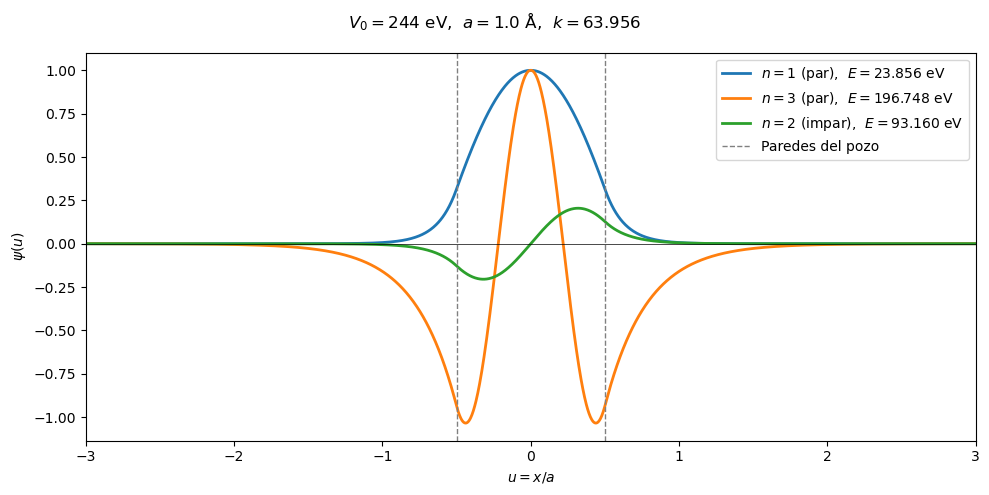

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Constantes físicas
# =========================
c       = 3e8            # m/s
mec2    = 0.511e6        # eV   (masa del electrón * c^2)
a       = 1e-10          # m
V0      = 244            # eV
hbarra  = 6.582e-16      # eV·s

# k = 2 m a^2 V0 / ħ^2  → usando m = mec2 / c^2
k = 2 * mec2 * a**2 * V0 / (hbarra**2 * c**2)

print(f"k = {k:.6f}")

# =========================
# Mallado
# =========================
u = np.linspace(0, 3, 1001)

# =========================
# Función C(u)
# =========================
def C_calc(u_val, alfa):
    if -0.5 < u_val < 0.5:
        return -k * alfa
    else:
        return k * (1 - alfa)

# =========================
# Integración por Euler
# =========================
def psi_calc(u, alfa, PAR=True):
    du   = u[1] - u[0]
    psi  = np.zeros_like(u)
    dpsi = np.zeros_like(u)

    # Condiciones iniciales
    if PAR:
        psi[0]  = 1.0
        dpsi[0] = 0.0
    else:
        psi[0]  = 0.0
        dpsi[0] = 1.0

    # Integración
    for i in range(1, len(u)):
        cval    = C_calc(u[i - 1], alfa)
        psi[i]  = psi[i - 1] + dpsi[i - 1] * du
        dpsi[i] = dpsi[i - 1] + cval * psi[i - 1] * du

    return psi

# =========================
# Valor final para shooting
# =========================
def psi_final(u, alfa, PAR=True):
    return psi_calc(u, alfa, PAR)[-1]

# =========================
# Búsqueda de autovalores
# =========================
def calc_alphas_euler(PAR=True, deltaAlfa=1e-4, tol=1e-12, max_iter=200):
    alphas = []

    alfa1 = 0.0
    val1  = psi_final(u, alfa1, PAR)

    while alfa1 < 1.0:
        alfa2 = alfa1 + deltaAlfa
        if alfa2 > 1.0:
            break

        val2 = psi_final(u, alfa2, PAR)

        # Detectamos cambio de signo
        if val1 * val2 <= 0:
            a_bis = alfa1
            b_bis = alfa2
            fa    = val1
            fb    = val2

            # Bisección
            for _ in range(max_iter):
                mid = 0.5 * (a_bis + b_bis)
                fm  = psi_final(u, mid, PAR)

                if abs(b_bis - a_bis) < tol:
                    break

                if fa * fm <= 0:
                    b_bis = mid
                    fb    = fm
                else:
                    a_bis = mid
                    fa    = fm

            alfaNew = 0.5 * (a_bis + b_bis)
            print(f"  Alfa = {alfaNew:.10f}  =>  E = {alfaNew * V0:.6f} eV")
            alphas.append(alfaNew)

            # Avanzamos para no quedarnos pegados en la misma raíz
            alfa1 = alfa2
            val1  = val2
        else:
            alfa1 = alfa2
            val1  = val2

    print(f"Total soluciones: {len(alphas)}\n")
    return alphas

# =========================
# Cálculo de autovalores
# =========================
t0 = time.perf_counter()

print("Soluciones PARES:")
alphas_par = calc_alphas_euler(PAR=True)

print("Soluciones IMPARES:")
alphas_impar = calc_alphas_euler(PAR=False)

t1 = time.perf_counter()

tiempo_total = t1 - t0
print(f"Tiempo total = {tiempo_total:.6f} s")

# =========================
# Gráfica de autofunciones
# =========================
fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle(f'$V_0={V0}$ eV,  $a={a*1e10:.1f}$ Å,  $k={k:.3f}$')

# Estados pares
n = 1
for i, alfa in enumerate(alphas_par):
    psi = psi_calc(u, alfa, PAR=True)
    color = plt.cm.tab10(i % 10)

    ax.plot(
        np.r_[-u[::-1], u],
        np.r_[ psi[::-1], psi],
        color=color,
        lw=2,
        label=f'$n={n}$ (par),  $E={alfa*V0:.3f}$ eV'
    )
    n += 2

# Estados impares
n = 2
for i, alfa in enumerate(alphas_impar):
    psi = psi_calc(u, alfa, PAR=False)
    color = plt.cm.tab10((len(alphas_par) + i) % 10)

    ax.plot(
        np.r_[-u[::-1], u],
        np.r_[-psi[::-1], psi],
        color=color,
        lw=2,
        label=f'$n={n}$ (impar),  $E={alfa*V0:.3f}$ eV'
    )
    n += 2

# Líneas guía
ax.axvline(-0.5, color='gray', linestyle='--', lw=1, label='Paredes del pozo')
ax.axvline( 0.5, color='gray', linestyle='--', lw=1)
ax.axhline(0,    color='black', lw=0.5)

ax.set_xlim(-3, 3)
ax.set_xlabel('$u = x/a$')
ax.set_ylabel(r'$\psi(u)$')
ax.legend()
plt.tight_layout()
plt.show()

k = 63.956171
Soluciones PARES (Numerov):
  Alfa = 0.0982311363  =>  E = 23.968397 eV
  Alfa = 0.8092648516  =>  E = 197.460624 eV
Total soluciones: 2

Soluciones IMPARES (Numerov):
  Alfa = 0.3834956273  =>  E = 93.572933 eV
Total soluciones: 1

Tiempo total = 37.397188 s


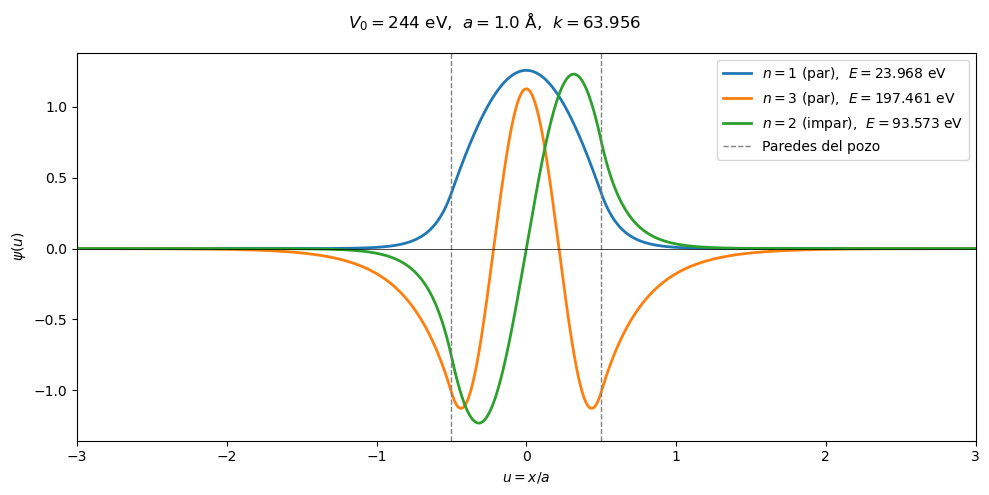

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Constantes físicas
# =========================
c       = 3e8            # m/s
mec2    = 0.511e6        # eV   (= m_e c^2)
a       = 1e-10          # m
V0      = 244            # eV
hbarra  = 6.582e-16      # eV·s

# k = 2 m a^2 V0 / ħ^2, con m = mec2 / c^2
k = 2 * mec2 * a**2 * V0 / (hbarra**2 * c**2)
print(f"k = {k:.6f}")

# =========================
# Mallado en media caja
# =========================
u = np.linspace(0, 3, 1001)

# =========================
# Función f(u) del método de Numerov
# ψ''(u) = f(u) ψ(u)
# =========================
def f_u(u_arr, alfa):
    V_arr = np.where(np.abs(u_arr) < 0.5, 0.0, V0)
    return k * (V_arr / V0 - alfa)

# =========================
# Integración por Numerov
# =========================
def psi_numerov(u, alfa, PAR=True):
    du  = u[1] - u[0]
    fu  = f_u(u, alfa)
    psi = np.zeros(len(u))

    # Condiciones iniciales
    if PAR:
        # ψ(0)=1, ψ'(0)=0
        psi[0] = 1.0
        # Taylor: ψ(du) ≈ ψ(0) + 1/2 ψ''(0) du^2 = 1 + 1/2 f(0) ψ(0) du^2
        psi[1] = psi[0] + 0.5 * fu[0] * psi[0] * du**2
    else:
        # ψ(0)=0, ψ'(0)=1  => ψ(du) ≈ du
        psi[0] = 0.0
        psi[1] = du

    # Recurrencia de Numerov
    for i in range(1, len(u) - 1):
        num = (
            2 * (1 + 5 * du**2 * fu[i] / 12) * psi[i]
            - (1 - du**2 * fu[i - 1] / 12) * psi[i - 1]
        )
        psi[i + 1] = num / (1 - du**2 * fu[i + 1] / 12)

    return psi

# =========================
# Valor final para shooting
# =========================
def psi_final(u, alfa, PAR=True):
    return psi_numerov(u, alfa, PAR)[-1]

# =========================
# Búsqueda de autovalores
# =========================
def calc_alphas_numerov(PAR=True, deltaAlfa=1e-4, tol=1e-12, max_iter=200):
    alphas = []

    alfa1 = 0.0
    val1  = psi_final(u, alfa1, PAR)

    while alfa1 < 1.0:
        alfa2 = alfa1 + deltaAlfa
        if alfa2 > 1.0:
            break

        val2 = psi_final(u, alfa2, PAR)

        # cambio de signo => hay raíz entre alfa1 y alfa2
        if val1 * val2 <= 0:
            a_bis = alfa1
            b_bis = alfa2
            fa    = val1
            fb    = val2

            for _ in range(max_iter):
                mid = 0.5 * (a_bis + b_bis)
                fm  = psi_final(u, mid, PAR)

                if abs(b_bis - a_bis) < tol:
                    break

                if fa * fm <= 0:
                    b_bis = mid
                    fb    = fm
                else:
                    a_bis = mid
                    fa    = fm

            alfaNew = 0.5 * (a_bis + b_bis)
            print(f"  Alfa = {alfaNew:.10f}  =>  E = {alfaNew * V0:.6f} eV")
            alphas.append(alfaNew)

            alfa1 = alfa2
            val1  = val2
        else:
            alfa1 = alfa2
            val1  = val2

    print(f"Total soluciones: {len(alphas)}\n")
    return alphas

# =========================
# Reconstrucción en caja completa
# =========================
def reconstruir_simetria(u_pos, psi_pos, PAR=True):
    if PAR:
        u_full   = np.r_[-u_pos[::-1], u_pos[1:]]
        psi_full = np.r_[ psi_pos[::-1], psi_pos[1:]]
    else:
        u_full   = np.r_[-u_pos[::-1], u_pos[1:]]
        psi_full = np.r_[-psi_pos[::-1], psi_pos[1:]]
    return u_full, psi_full

# =========================
# Normalización simple
# =========================
def normalizar(u, psi):
    norma = np.sqrt(np.trapezoid(psi**2, u))
    if norma != 0:
        return psi / norma
    return psi

# =========================
# Cálculo de autovalores
# =========================
t0 = time.perf_counter()

print("Soluciones PARES (Numerov):")
alphas_par = calc_alphas_numerov(PAR=True)

print("Soluciones IMPARES (Numerov):")
alphas_impar = calc_alphas_numerov(PAR=False)

t1 = time.perf_counter()

tiempo_total = t1 - t0
print(f"Tiempo total = {tiempo_total:.6f} s")

# =========================
# Gráfica de autofunciones
# =========================
fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle(f'$V_0={V0}$ eV,  $a={a*1e10:.1f}$ Å,  $k={k:.3f}$')

# Pares
n = 1
for i, alfa in enumerate(alphas_par):
    psi_pos = psi_numerov(u, alfa, PAR=True)
    u_full, psi_full = reconstruir_simetria(u, psi_pos, PAR=True)
    psi_full = normalizar(u_full, psi_full)

    ax.plot(
        u_full, psi_full,
        color=plt.cm.tab10(i % 10),
        lw=2,
        label=f'$n={n}$ (par),  $E={alfa*V0:.3f}$ eV'
    )
    n += 2

# Impares
n = 2
for i, alfa in enumerate(alphas_impar):
    psi_pos = psi_numerov(u, alfa, PAR=False)
    u_full, psi_full = reconstruir_simetria(u, psi_pos, PAR=False)
    psi_full = normalizar(u_full, psi_full)

    ax.plot(
        u_full, psi_full,
        color=plt.cm.tab10((len(alphas_par) + i) % 10),
        lw=2,
        label=f'$n={n}$ (impar),  $E={alfa*V0:.3f}$ eV'
    )
    n += 2

# Líneas guía
ax.axvline(-0.5, color='gray', linestyle='--', lw=1, label='Paredes del pozo')
ax.axvline( 0.5, color='gray', linestyle='--', lw=1)
ax.axhline(0, color='black', lw=0.5)

ax.set_xlim(-3, 3)
ax.set_xlabel('$u = x/a$')
ax.set_ylabel(r'$\psi(u)$')
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
import numpy as np
import time

# =========================================================
# CONSTANTES FÍSICAS
# =========================================================

c       = 3e8            # m/s
mec2    = 0.511e6        # eV   (= m_e c^2)
a       = 1e-10          # m
V0      = 244            # eV
hbarra  = 6.582e-16      # eV·s

# k = 2 m a^2 V0 / ħ^2, usando m = mec2 / c^2
k = 2 * mec2 * a**2 * V0 / (hbarra**2 * c**2)

print(f"k = {k:.6f}")


# =========================================================
# EULER
# =========================================================

def C_calc(u_val, alfa, k):
    if -0.5 < u_val < 0.5:
        return -k * alfa
    else:
        return k * (1 - alfa)


def psi_calc_euler(u, alfa, k, PAR=True):
    du   = u[1] - u[0]
    psi  = np.zeros_like(u)
    dpsi = np.zeros_like(u)

    if PAR:
        psi[0]  = 1.0
        dpsi[0] = 0.0
    else:
        psi[0]  = 0.0
        dpsi[0] = 1.0

    for i in range(1, len(u)):
        cval    = C_calc(u[i - 1], alfa, k)
        psi[i]  = psi[i - 1] + dpsi[i - 1] * du
        dpsi[i] = dpsi[i - 1] + cval * psi[i - 1] * du

    return psi


def psi_final_euler(u, alfa, k, PAR=True):
    return psi_calc_euler(u, alfa, k, PAR)[-1]


def calc_alphas_euler(u, k, V0, PAR=True, deltaAlfa=1e-4, tol=1e-12, max_iter=200, verbose=False):
    alphas = []

    alfa1 = 0.0
    val1  = psi_final_euler(u, alfa1, k, PAR)

    while alfa1 < 1.0:
        alfa2 = alfa1 + deltaAlfa
        if alfa2 > 1.0:
            break

        val2 = psi_final_euler(u, alfa2, k, PAR)

        if val1 * val2 <= 0:
            a_bis = alfa1
            b_bis = alfa2
            fa    = val1

            for _ in range(max_iter):
                mid = 0.5 * (a_bis + b_bis)
                fm  = psi_final_euler(u, mid, k, PAR)

                if abs(b_bis - a_bis) < tol:
                    break

                if fa * fm <= 0:
                    b_bis = mid
                else:
                    a_bis = mid
                    fa    = fm

            alfa_new = 0.5 * (a_bis + b_bis)
            alphas.append(alfa_new)

            if verbose:
                print(f"  Alfa = {alfa_new:.10f}  =>  E = {alfa_new * V0:.6f} eV")

            alfa1 = alfa2
            val1  = val2
        else:
            alfa1 = alfa2
            val1  = val2

    if verbose:
        print(f"Total soluciones Euler ({'par' if PAR else 'impar'}): {len(alphas)}\n")

    return alphas


# =========================================================
# NUMEROV
# =========================================================

def f_u(u_arr, alfa, k, V0):
    V_arr = np.where(np.abs(u_arr) < 0.5, 0.0, V0)
    return k * (V_arr / V0 - alfa)


def psi_numerov(u, alfa, k, V0, PAR=True):
    du  = u[1] - u[0]
    fu  = f_u(u, alfa, k, V0)
    psi = np.zeros(len(u))

    if PAR:
        psi[0] = 1.0
        psi[1] = psi[0] + 0.5 * fu[0] * psi[0] * du**2
    else:
        psi[0] = 0.0
        psi[1] = du

    for i in range(1, len(u) - 1):
        num = (
            2 * (1 + 5 * du**2 * fu[i] / 12) * psi[i]
            - (1 - du**2 * fu[i - 1] / 12) * psi[i - 1]
        )
        psi[i + 1] = num / (1 - du**2 * fu[i + 1] / 12)

    return psi


def psi_final_numerov(u, alfa, k, V0, PAR=True):
    return psi_numerov(u, alfa, k, V0, PAR)[-1]


def calc_alphas_numerov(u, k, V0, PAR=True, deltaAlfa=1e-4, tol=1e-12, max_iter=200, verbose=False):
    alphas = []

    alfa1 = 0.0
    val1  = psi_final_numerov(u, alfa1, k, V0, PAR)

    while alfa1 < 1.0:
        alfa2 = alfa1 + deltaAlfa
        if alfa2 > 1.0:
            break

        val2 = psi_final_numerov(u, alfa2, k, V0, PAR)

        if val1 * val2 <= 0:
            a_bis = alfa1
            b_bis = alfa2
            fa    = val1

            for _ in range(max_iter):
                mid = 0.5 * (a_bis + b_bis)
                fm  = psi_final_numerov(u, mid, k, V0, PAR)

                if abs(b_bis - a_bis) < tol:
                    break

                if fa * fm <= 0:
                    b_bis = mid
                else:
                    a_bis = mid
                    fa    = fm

            alfa_new = 0.5 * (a_bis + b_bis)
            alphas.append(alfa_new)

            if verbose:
                print(f"  Alfa = {alfa_new:.10f}  =>  E = {alfa_new * V0:.6f} eV")

            alfa1 = alfa2
            val1  = val2
        else:
            alfa1 = alfa2
            val1  = val2

    if verbose:
        print(f"Total soluciones Numerov ({'par' if PAR else 'impar'}): {len(alphas)}\n")

    return alphas


# =========================================================
# UTILIDADES DE COMPARACIÓN
# =========================================================

def juntar_estados(alphas_par, alphas_impar, V0):
    estados = []

    n = 1
    for a in alphas_par:
        estados.append((n, "par", a, a * V0))
        n += 2

    n = 2
    for a in alphas_impar:
        estados.append((n, "impar", a, a * V0))
        n += 2

    estados.sort(key=lambda x: x[3])

    estados_ordenados = []
    for i, (_, paridad, alpha, E) in enumerate(estados, start=1):
        estados_ordenados.append((i, paridad, alpha, E))

    return estados_ordenados


def medir_tiempo(func, repeticiones=5):
    tiempos = []
    resultado = None

    for _ in range(repeticiones):
        t0 = time.perf_counter()
        resultado = func()
        t1 = time.perf_counter()
        tiempos.append(t1 - t0)

    return resultado, np.mean(tiempos), np.std(tiempos)


def comparar_estados(est_euler, est_num):
    print("\n=== Comparación Euler vs Numerov ===")
    print(f"{'n':>2}  {'Par':>6}  {'E Euler (eV)':>14}  {'E Numerov (eV)':>16}  {'|ΔE| (eV)':>12}  {'Dif. rel.':>12}")

    n_estados = min(len(est_euler), len(est_num))

    for i in range(n_estados):
        n, par_e, _, Ee = est_euler[i]
        _, par_n, _, En = est_num[i]

        diff = abs(Ee - En)
        rel  = diff / abs(En) if En != 0 else 0.0

        print(f"{n:2d}  {par_e:>6}  {Ee:14.6f}  {En:16.6f}  {diff:12.6f}  {rel:12.6e}")


def imprimir_tiempos(t_euler, s_euler, t_num, s_num):
    print("\n=== Coste computacional ===")
    print(f"{'Método':>10}  {'Tiempo medio (s)':>20}  {'Desv. típica':>15}")
    print(f"{'Euler':>10}  {t_euler:20.6f}  {s_euler:15.6f}")
    print(f"{'Numerov':>10}  {t_num:20.6f}  {s_num:15.6f}")


# =========================================================
# WRAPPERS
# =========================================================

def ejecutar_euler(u, k, V0, deltaAlfa=1e-4, tol=1e-12, max_iter=200, verbose=False):
    alphas_par = calc_alphas_euler(u, k, V0, PAR=True,  deltaAlfa=deltaAlfa, tol=tol, max_iter=max_iter, verbose=verbose)
    alphas_imp = calc_alphas_euler(u, k, V0, PAR=False, deltaAlfa=deltaAlfa, tol=tol, max_iter=max_iter, verbose=verbose)
    return juntar_estados(alphas_par, alphas_imp, V0)


def ejecutar_numerov(u, k, V0, deltaAlfa=1e-4, tol=1e-12, max_iter=200, verbose=False):
    alphas_par = calc_alphas_numerov(u, k, V0, PAR=True,  deltaAlfa=deltaAlfa, tol=tol, max_iter=max_iter, verbose=verbose)
    alphas_imp = calc_alphas_numerov(u, k, V0, PAR=False, deltaAlfa=deltaAlfa, tol=tol, max_iter=max_iter, verbose=verbose)
    return juntar_estados(alphas_par, alphas_imp, V0)


# =========================================================
# CASO BASE
# =========================================================

def caso_base():
    u_max = 3.0
    N = 1001
    u = np.linspace(0, u_max, N)

    estados_euler, t_euler, s_euler = medir_tiempo(
        lambda: ejecutar_euler(u, k, V0),
        repeticiones=5
    )

    estados_num, t_num, s_num = medir_tiempo(
        lambda: ejecutar_numerov(u, k, V0),
        repeticiones=5
    )

    comparar_estados(estados_euler, estados_num)
    imprimir_tiempos(t_euler, s_euler, t_num, s_num)


# =========================================================
# BARRIDO EN N
# =========================================================

def barrido_N():
    u_max = 3.0
    N_values = [501, 1001, 2001, 4001]

    print("\n=== Barrido en N ===")
    print(f"{'N':>6}  {'n':>2}  {'E Euler':>12}  {'E Numerov':>12}  {'Rel':>10}  {'tE (s)':>10}  {'tN (s)':>10}")

    for N in N_values:
        u = np.linspace(0, u_max, N)

        estados_euler, t_euler, _ = medir_tiempo(
            lambda: ejecutar_euler(u, k, V0),
            repeticiones=3
        )

        estados_num, t_num, _ = medir_tiempo(
            lambda: ejecutar_numerov(u, k, V0),
            repeticiones=3
        )

        n_estados = min(len(estados_euler), len(estados_num))

        for i in range(n_estados):
            Ee = estados_euler[i][3]
            En = estados_num[i][3]
            rel = abs(Ee - En) / abs(En) if En != 0 else 0.0

            print(f"{N:6d}  {i+1:2d}  {Ee:12.6f}  {En:12.6f}  {rel:10.6e}  {t_euler:10.4f}  {t_num:10.4f}")


# =========================================================
# BARRIDO EN u_max
# =========================================================

def barrido_umax():
    N = 1001
    umax_values = [2.0, 3.0, 4.0, 5.0]

    print("\n=== Barrido en u_max ===")
    print(f"{'u_max':>6}  {'n':>2}  {'E Euler':>12}  {'E Numerov':>12}  {'Rel':>10}")

    for u_max in umax_values:
        u = np.linspace(0, u_max, N)

        estados_euler = ejecutar_euler(u, k, V0)
        estados_num   = ejecutar_numerov(u, k, V0)

        n_estados = min(len(estados_euler), len(estados_num))

        for i in range(n_estados):
            Ee = estados_euler[i][3]
            En = estados_num[i][3]
            rel = abs(Ee - En) / abs(En) if En != 0 else 0.0

            print(f"{u_max:6.2f}  {i+1:2d}  {Ee:12.6f}  {En:12.6f}  {rel:10.6e}")


# =========================================================
# BARRIDO EN TOL
# =========================================================

def barrido_tol():
    u_max = 3.0
    N = 1001
    tol_values = [1e-6, 1e-8, 1e-10, 1e-12]
    u = np.linspace(0, u_max, N)

    print("\n=== Barrido en tolerancia ===")
    print(f"{'tol':>10}  {'n':>2}  {'E Euler':>12}  {'E Numerov':>12}  {'Rel':>10}")

    for tol in tol_values:
        estados_euler = ejecutar_euler(u, k, V0, tol=tol)
        estados_num   = ejecutar_numerov(u, k, V0, tol=tol)

        n_estados = min(len(estados_euler), len(estados_num))

        for i in range(n_estados):
            Ee = estados_euler[i][3]
            En = estados_num[i][3]
            rel = abs(Ee - En) / abs(En) if En != 0 else 0.0

            print(f"{tol:10.1e}  {i+1:2d}  {Ee:12.6f}  {En:12.6f}  {rel:10.6e}")


# =========================================================
# MAIN
# =========================================================

if __name__ == "__main__":
    caso_base()
    barrido_N()
    barrido_umax()
    barrido_tol()

k = 63.956171

=== Comparación Euler vs Numerov ===
 n     Par    E Euler (eV)    E Numerov (eV)     |ΔE| (eV)     Dif. rel.
 1     par       23.856017         23.968397      0.112381  4.688703e-03
 2   impar       93.159867         93.572933      0.413066  4.414375e-03
 3     par      196.748016        197.460624      0.712608  3.608860e-03

=== Coste computacional ===
    Método      Tiempo medio (s)     Desv. típica
     Euler             23.326474         0.545964
   Numerov             37.629301         0.730892

=== Barrido en N ===
     N   n       E Euler     E Numerov         Rel      tE (s)      tN (s)
   501   1     23.633437     23.853585  9.229150e-03     11.1280     19.2687
   501   2     92.348974     93.144184  8.537403e-03     11.1280     19.2687
   501   3    195.364271    196.703651  6.809126e-03     11.1280     19.2687
  1001   1     23.856017     23.968397  4.688703e-03     24.1344     36.4499
  1001   2     93.159867     93.572933  4.414375e-03     24.1344     36.